In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
twicter_data = pd.read_csv("twitter_training.csv", header=None, names=["ID", "Brand", "Sentiment", "Text"])
twicter_data

,ID,Brand,Sentiment,Text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
...,...,...,...,...
74677,9200,Nvidia,Positive,Just realized that the Windows partition of my...
74678,9200,Nvidia,Positive,Just realized that my Mac window partition is ...
74679,9200,Nvidia,Positive,Just realized the windows partition of my Mac ...
74680,9200,Nvidia,Positive,Just realized between the windows partition of...


In [3]:
twicter_data.head()

,ID,Brand,Sentiment,Text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [4]:
twicter_data.columns

Index(['ID', 'Brand', 'Sentiment', 'Text'], dtype='object')

In [5]:
twicter_data.shape

(74682, 4)

## data cleaning

In [6]:
twicter_data.isna().sum()

ID             0
Brand          0
Sentiment      0
Text         686
dtype: int64

In [7]:
twicter_data.duplicated().sum()

np.int64(2700)

In [8]:
twicter_data["Sentiment"].value_counts()

Sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64

In [9]:
twicter_data.dropna(subset=["Text"], inplace=True)

In [10]:
twicter_data.drop_duplicates(inplace=True)

In [11]:
print("The after null values: ", twicter_data.isna().sum())
print("The after duplicated values: ", twicter_data.duplicated().sum())

The after null values:  ID           0
Brand        0
Sentiment    0
Text         0
dtype: int64
The after duplicated values:  0


In [12]:
twicter_data.reset_index(drop=True, inplace=True)


In [13]:
twicter_data.shape

(71656, 4)

# data virsuvalization

In [14]:
twicter_data_counts = twicter_data["Sentiment"].value_counts()
twicter_data_counts

Sentiment
Negative      21698
Positive      19713
Neutral       17708
Irrelevant    12537
Name: count, dtype: int64

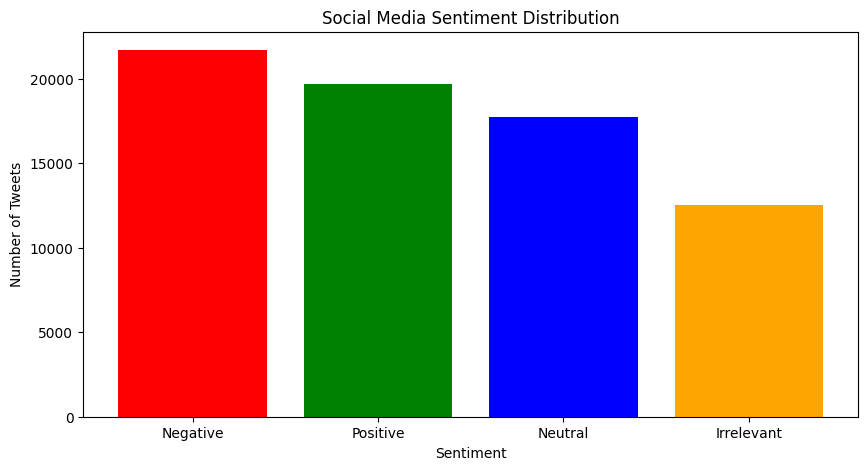

In [15]:
plt.figure(figsize=(10,5))

plt.bar(
    twicter_data_counts.index,
    twicter_data_counts.values,
    color = ["red","green","blue", "orange"]
)
plt.title("Social Media Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.show()
plt.show()

# Brand-wise Sentiment Count

In [16]:
brand_sentiment = pd.crosstab(
    twicter_data.Brand,
    twicter_data.Sentiment
)
brand_sentiment.head()

Sentiment,Irrelevant,Negative,Neutral,Positive
Brand,,,,
Amazon,185,565,1197,302
ApexLegends,185,574,913,606
AssassinsCreed,256,365,153,1382
Battlefield,907,445,342,561
Borderlands,238,415,581,972


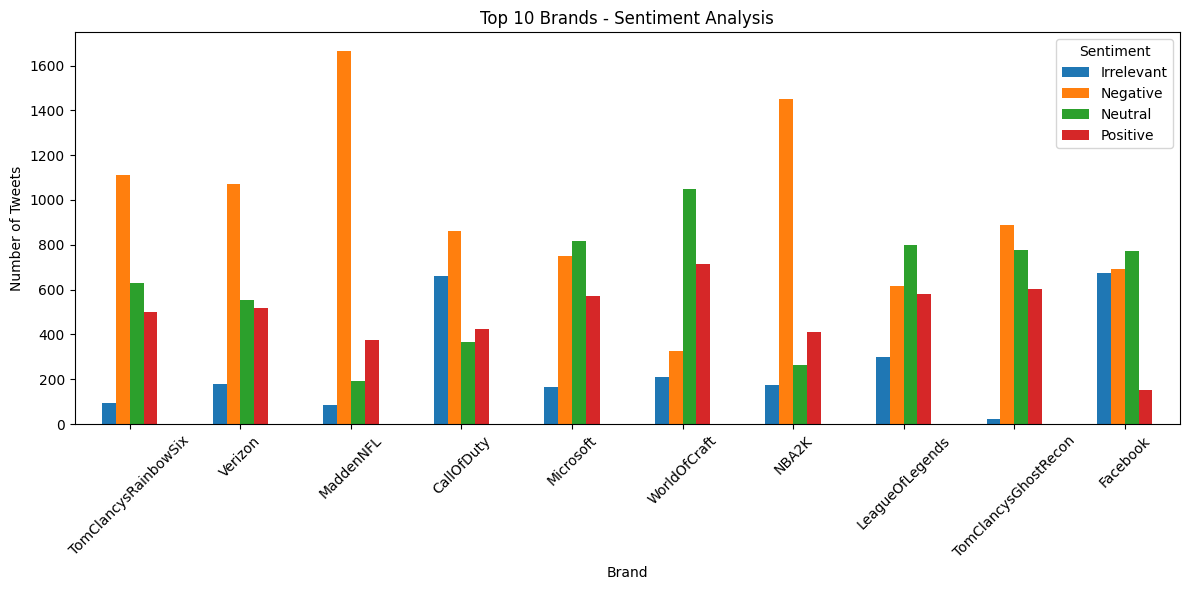

In [17]:
top_brands = twicter_data["Brand"].value_counts().head(10).index

brand_sentiment.loc[top_brands].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Top 10 Brands - Sentiment Analysis")
plt.xlabel("Brand")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=45)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

# Brand-wise Sentiment Percentage Analysis

In [18]:
brand_percentage = pd.crosstab(
    twicter_data.Brand,
    twicter_data.Sentiment,
    normalize="index"
)*100

brand_percentage.head(10).round(2)

Sentiment,Irrelevant,Negative,Neutral,Positive
Brand,,,,
Amazon,8.23,25.12,53.22,13.43
ApexLegends,8.12,25.20,40.08,26.60
AssassinsCreed,11.87,16.93,7.10,64.10
Battlefield,40.22,19.73,15.17,24.88
Borderlands,10.79,18.81,26.34,44.06
CS-GO,28.25,15.26,23.83,32.67
CallOfDuty,28.52,37.21,15.86,18.41
CallOfDutyBlackopsColdWar,24.31,24.09,15.17,36.44
Cyberpunk2077,21.01,16.55,20.97,41.47


# Visualize Sentiment Percentage

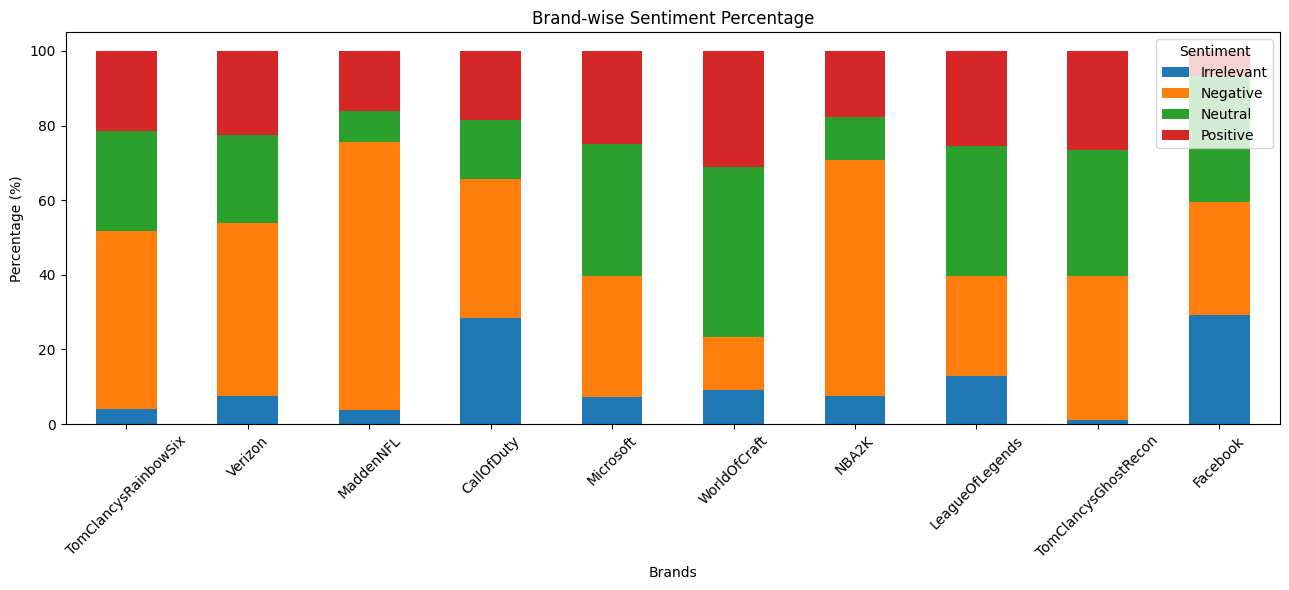

In [19]:
top_brands = twicter_data["Brand"].value_counts().head(10).index

brand_percentage.loc[top_brands].plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6)
)

plt.title("Brand-wise Sentiment Percentage")
plt.xlabel("Brands")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

In [20]:
positive_rank = brand_percentage["Positive"].sort_values(
    ascending=False
)

print(positive_rank.head(5).round(2))

Brand
AssassinsCreed            64.10
Borderlands               44.06
Cyberpunk2077             41.47
RedDeadRedemption(RDR)    41.07
PlayStation5(PS5)         40.77
Name: Positive, dtype: float64


In [21]:
negative_rank = brand_percentage["Negative"].sort_values(
    ascending=False
)

print(negative_rank.head(5).round(2))

Brand
MaddenNFL               71.92
NBA2K                   63.07
FIFA                    50.36
TomClancysRainbowSix    47.68
Verizon                 46.14
Name: Negative, dtype: float64


### Project Conclusion

This project analyzed social media sentiment patterns using the Twitter Entity Sentiment Analysis dataset.

**Key Findings:**
- Cleaned the dataset by removing missing text values and duplicate records.
- Analyzed 71,656 records after data cleaning.
- Visualized sentiment distribution across different brands and topics.
- AssassinsCreed recorded the highest positive sentiment percentage (64.10%).
- MaddenNFL recorded the highest negative sentiment percentage (71.92%).
- Brand-wise percentage analysis helped compare sentiment patterns across different topics.

**Tools Used:** Python, Pandas, Matplotlib, Jupyter Notebook.

**Conclusion:** Exploratory sentiment analysis helps identify patterns in labelled social media discussions and highlights topics receiving relatively positive or negative reactions. These findings can support further investigation into audience attitudes and brand perception.